# 02 · EDA complementario: calidad, atributos de tienda, promoción y ruido
Complementa `01_eda.ipynb` con las pruebas que sustentan las decisiones de modelado:
1. ¿Los nulos son aleatorios o estructurados?
2. ¿Qué campos son consistentes entre sí? (monto, transacciones, ticket)
3. ¿El calendario es confiable? ¿Los valores extremos son errores o eventos reales?
4. ¿Qué atributos de tienda importan y para qué (nivel vs. dinámica)?
5. ¿La promoción se asignó de forma aleatoria? (pruebas formales)
6. ¿Cuánto error es irreducible y a qué granularidad tiene sentido exigir una meta?

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'retina'

from scipy import stats
from src.data.load import load_transactions, load_stores, load_calendar
from src.data.preprocess import build_panel
from src.models.evaluate import wape, mape, bias
plt.rcParams.update({'figure.figsize': (10, 3.4), 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 140, 'display.max_columns', 30, 'display.float_format', '{:,.3f}'.format)
rng = np.random.default_rng(0)
t, s, c = load_transactions(), load_stores(), load_calendar()
p = build_panel(t, s, c)
obs = p[~p.is_missing_row].copy()          # filas realmente observadas
obs['serie'] = obs.store_id + '|' + obs.category
print(obs.shape)

(203958, 40)


## 1. Nulos: ¿aleatorios (MCAR) o estructurados?

In [2]:
print('¿cash_transactions y amount_cash son nulos siempre juntos?')
print(pd.crosstab(t.cash_transactions.isna().rename('cash_tx nulo'), t.amount_cash.isna().rename('amount_cash nulo')))
flags = obs[['cash_missing', 'units_missing', 'ticket_missing']].astype(int)
print('\nFilas con nulo simultáneo (diagonal = nulos de la columna):'); (flags.T @ flags)

¿cash_transactions y amount_cash son nulos siempre juntos?
amount_cash nulo   False  True 
cash_tx nulo                   
False             191835      0
True                   0  12123

Filas con nulo simultáneo (diagonal = nulos de la columna):


,cash_missing,units_missing,ticket_missing
cash_missing,12123,349,4874
units_missing,349,6118,150
ticket_missing,4874,150,4874


In [3]:
base = obs.cash_missing.mean()
seg = {}
for col in ['category', 'store_format', 'region', 'socioeconomic_level', 'has_promotion', 'is_official_holiday', 'day_of_week', 'month']:
    r = obs.groupby(col, observed=True).cash_missing.mean() * 100
    seg[col] = f'{r.min():.1f}% – {r.max():.1f}%'
print(f'Tasa de nulos de efectivo por segmento (mín – máx entre niveles). Global: {base:.2%}')
print(pd.Series(seg, name='rango').to_string())

# dispersión entre tiendas vs lo esperable por azar
st = obs.groupby('store_id').cash_missing.agg(['mean', 'size'])
sd_exp = np.sqrt(base * (1 - base) / st['size'].mean()); z = (st['mean'] - base) / sd_exp
print(f'\nDesv. estándar entre tiendas: observada {st["mean"].std()*100:.2f} pp | esperada por azar {sd_exp*100:.2f} pp | |z| máx {z.abs().max():.2f}')

# persistencia: ¿un nulo hoy anticipa un nulo mañana?
q = obs.sort_values(['serie', 'date'])
for col in ['cash_missing', 'units_missing', 'ticket_missing']:
    prev = q.groupby('serie')[col].shift()
    print(f'{col:14s} P(nulo)={q[col].mean():.4f} | P(nulo | nulo ayer)={q.loc[prev == True, col].mean():.4f} | P(nulo | no nulo ayer)={q.loc[prev == False, col].mean():.4f}')

Tasa de nulos de efectivo por segmento (mín – máx entre niveles). Global: 5.94%
category               5.8% – 6.1%
store_format           5.7% – 6.0%
region                 5.8% – 6.2%
socioeconomic_level    5.8% – 6.1%
has_promotion          5.9% – 6.0%
is_official_holiday    5.9% – 6.4%
day_of_week            5.7% – 6.1%
month                  5.6% – 6.4%

Desv. estándar entre tiendas: observada 0.55 pp | esperada por azar 0.47 pp | |z| máx 2.30
cash_missing   P(nulo)=0.0594 | P(nulo | nulo ayer)=0.0571 | P(nulo | no nulo ayer)=0.0596
units_missing  P(nulo)=0.0300 | P(nulo | nulo ayer)=0.0287 | P(nulo | no nulo ayer)=0.0300
ticket_missing P(nulo)=0.0239 | P(nulo | nulo ayer)=0.0222 | P(nulo | no nulo ayer)=0.0239


**Lectura.** Los nulos se comportan como fallas puntuales independientes (MCAR), no como apagones:
- `cash_transactions` y `amount_cash` son nulos **siempre juntos** (un solo evento: falla en el registro de efectivo). `units_sold` y `avg_ticket` aparentan ser eventos independientes (el cruce fuera de la diagonal es pequeño).
- La tasa de nulos de efectivo es ≈ uniforme entre segmentos (5.6 %–6.4 %); la dispersión entre tiendas es la esperable por azar (0.55 pp observado vs. 0.47 pp esperado, |z| máx 2.3) y **un nulo ayer no eleva la probabilidad hoy** (5.7 % vs. 6.0 %).

**Decisión.** Como no hay estructura que explotar y son variables del mismo día que se pronostica, se conservan como `NaN` con bandera (ya construidas en el panel) y no se usan como features.

## 2. Consistencias entre monto, transacciones y ticket

In [4]:
d = t.dropna(subset=['cash_transactions']).copy()
d['paid'] = d.cash_transactions + d.card_transactions
d['inflada'] = d.total_transactions != d.paid
print('amount_total vs efectivo + tarjeta (filas comparables):', int(t.amount_cash.notna().sum()),
      '| diferencia máx. abs:', f'{(t.amount_total - t.amount_cash - t.amount_card).abs().max():.1e}', 'MXN')
print('\nhas_promotion × (total_transactions ≠ efectivo + tarjeta):')
print(pd.crosstab(d.has_promotion, d.inflada.rename('total ≠ efectivo+tarjeta'), margins=True))
ex = (d.total_transactions / d.paid - 1)[d.has_promotion == 1]
print('\nExceso sobre efectivo + tarjeta en filas con promoción:'); print(ex.describe(percentiles=[.05, .5, .95]).round(3).to_frame().T.to_string())

amount_total vs efectivo + tarjeta (filas comparables): 191835 | diferencia máx. abs: 3.5e-10 MXN

has_promotion × (total_transactions ≠ efectivo + tarjeta):
total ≠ efectivo+tarjeta   False   True     All
has_promotion                                  
0                         153540      0  153540
1                              0  38295   38295
All                       153540  38295  191835

Exceso sobre efectivo + tarjeta en filas con promoción:
       count  mean   std   min    5%   50%   95%   max
0 38,295.000 0.223 0.072 0.083 0.111 0.222 0.336 0.350


In [5]:
tk = t.dropna(subset=['avg_ticket']).copy()
tk['paid'] = tk.cash_transactions + tk.card_transactions
tk['mm_total'] = (tk.amount_total / tk.total_transactions - tk.avg_ticket).abs() > 0.011
tk['mm_paid'] = (tk.amount_total / tk.paid - tk.avg_ticket).abs() > 0.011
print(f'avg_ticket coincide con monto / total_transactions en {(~tk.mm_total).mean():.1%} de las filas')
print(f'avg_ticket coincide con monto / (efectivo+tarjeta)  en {(~tk.mm_paid[tk.paid.notna()]).mean():.1%} de las filas con efectivo')
print('\nDonde NO coincide con total_transactions:'); print(pd.crosstab(tk.has_promotion, tk.mm_total.rename('ticket ≠ monto/total_tx')))
ok = tk.dropna(subset=['paid']); err = (ok.amount_total / ok.avg_ticket - ok.paid).abs()
print(f'\nReconstrucción de transacciones pagadas como monto/avg_ticket: error máx {err.max():.2f} transacciones')

avg_ticket coincide con monto / total_transactions en 80.0% de las filas
avg_ticket coincide con monto / (efectivo+tarjeta)  en 100.0% de las filas con efectivo

Donde NO coincide con total_transactions:
ticket ≠ monto/total_tx   False  True 
has_promotion                         
0                        159298      0
1                             0  39786

Reconstrucción de transacciones pagadas como monto/avg_ticket: error máx 0.26 transacciones


In [6]:
cmp = d.assign(**{'efectivo+tarjeta': d.paid}).groupby('has_promotion')[['total_transactions', 'efectivo+tarjeta', 'amount_total', 'units_sold', 'avg_ticket']].mean().T
cmp.columns = ['sin promo', 'con promo']; cmp['diferencia %'] = (cmp['con promo'] / cmp['sin promo'] - 1) * 100
print('Medias simples (sin controles) por estatus de promoción:'); cmp

Medias simples (sin controles) por estatus de promoción:


,sin promo,con promo,diferencia %
total_transactions,586.833,718.200,22.386
efectivo+tarjeta,586.833,587.063,0.039
amount_total,"170,495.010","170,355.425",-0.082
units_sold,"1,174.027","1,176.326",0.196
avg_ticket,412.041,410.783,-0.305


**Lectura.**
- `amount_total` = efectivo + tarjeta de forma exacta (diferencia máxima 3.5e-10 MXN): el target es confiable.
- `total_transactions` ≠ efectivo + tarjeta **si y solo si** `has_promotion = 1`: 38,295 de 38,295 filas con promoción y 0 de 153,540 sin ella. El exceso es de entre ≈ 8 % y 35 % (media 22 %).
- `avg_ticket` coincide **siempre** con `amount_total / (efectivo + tarjeta)` y solo discrepa de `amount_total / total_transactions` en filas con promoción. Es decir: monto, ticket y transacciones pagadas son coherentes entre sí y **el campo que se aparta es `total_transactions`, solo con promoción**.
- Con promoción, `total_transactions` sube ≈ 22 %, pero transacciones pagadas, monto, unidades y ticket no cambian (|dif.| ≤ 0.3 %). Si la promoción atrajera más clientes, esos clientes pagarían y el monto subiría.
- Cuando falta el efectivo, las transacciones pagadas se reconstruyen como `monto / avg_ticket` con error < 0.3 transacciones.

**Hipótesis (no verificable con estos datos):** en días con promoción se cuentan transacciones sin monto asociado (p. ej. canjes de cupón de valor cero o conteos duplicados). Se documenta como supuesto.

**Decisión.** `total_transactions` no es válido como target ni como medida de uplift. El uplift se mide sobre `amount_total`.

## 3. Calendario y valores extremos

In [7]:
cc = c.copy()
reglas = {
    'day_of_week coincide con la fecha': (cc.date.dt.dayofweek == cc.day_of_week).all(),
    'is_weekend = sábado o domingo': ((cc.day_of_week >= 5) == cc.is_weekend).all(),
    'week_of_year = semana ISO': (cc.date.dt.isocalendar().week.astype(int) == cc.week_of_year).all(),
    'is_payday = día 15 o fin de mes': (((cc.date.dt.day == 15) | cc.date.dt.is_month_end) == cc.is_payday).all(),
    'is_navidad_season = 15-dic a 6-ene': ((((cc.date.dt.month == 12) & (cc.date.dt.day >= 15)) | ((cc.date.dt.month == 1) & (cc.date.dt.day <= 6))) == cc.is_navidad_season).all(),
}
print(pd.Series(reglas, name='cumple').to_string())
print('\nBuen Fin     :', cc.loc[cc.is_buen_fin, 'date'].dt.strftime('%Y-%m-%d').tolist())
print('Semana Santa :', cc.loc[cc.is_semana_santa, 'date'].dt.strftime('%Y-%m-%d').tolist())
print('Días marcados is_holiday que además son Buen Fin:', int((cc.is_holiday & cc.is_buen_fin).sum()), '→', cc.loc[cc.is_holiday & cc.is_buen_fin, 'holiday_name'].unique().tolist())
print('Festivos:', sorted(cc.holiday_name.dropna().unique()))

day_of_week coincide con la fecha     True
is_weekend = sábado o domingo         True
week_of_year = semana ISO             True
is_payday = día 15 o fin de mes       True
is_navidad_season = 15-dic a 6-ene    True

Buen Fin     : ['2023-11-17', '2023-11-18', '2023-11-19', '2023-11-20']
Semana Santa : ['2023-04-06', '2023-04-07']
Días marcados is_holiday que además son Buen Fin: 4 → ['Buen Fin', 'Revolución Mexicana / Buen Fin']
Festivos: ['Año Nuevo', 'Buen Fin', 'Día de Muertos', 'Día de la Constitución', 'Día de la Independencia', 'Día del Trabajo', 'Fin de Año', 'Jueves Santo', 'Natalicio Benito Juárez', 'Navidad', 'Nochebuena', 'Revolución Mexicana / Buen Fin', 'Viernes Santo', 'Virgen de Guadalupe']


In [8]:
q = obs.sort_values(['serie', 'date']).copy()
q['med28'] = q.groupby('serie').amount_total.transform(lambda x: x.rolling(28, center=True, min_periods=7).median())
q['ratio'] = q.amount_total / q.med28
print(q.ratio.describe(percentiles=[.001, .01, .99, .999]).round(2).to_frame().T.to_string())
names = c.holiday_name.fillna('')
ev_dates = c.loc[c.is_buen_fin | names.str.contains('Nochebuena|Fin de Año|Navidad'), 'date']
alto, bajo = q[q.ratio > 3], q[q.ratio < 0.3]
print(f'\nFilas con ratio > 3: {len(alto):,} | % en Buen Fin/Nochebuena/Navidad/Fin de Año: {alto.date.isin(ev_dates).mean():.1%}')
print(f'Filas con ratio < 0.3: {len(bajo):,} | fechas más frecuentes:', bajo.date.dt.strftime('%Y-%m-%d').value_counts().head(4).to_dict())
print('Plausibilidad → unidades/transacción:', round((obs.units_sold / obs.total_transactions).min(), 2), 'a', round((obs.units_sold / obs.total_transactions).max(), 2),
      '| ticket:', round(obs.avg_ticket.min()), 'a', round(obs.avg_ticket.max()), '| duplicados:', int(t.duplicated(['date', 'store_id', 'category']).sum()),
      '| montos idénticos al día anterior:', int((t.sort_values(['store_id', 'category', 'date']).groupby(['store_id', 'category']).amount_total.diff() == 0).sum()))

            count  mean   std   min  0.1%    1%   99%  99.9%   max
ratio 203,958.000 1.090 0.450 0.120 0.220 0.450 2.740  4.580 6.950

Filas con ratio > 3: 1,693 | % en Buen Fin/Nochebuena/Navidad/Fin de Año: 98.3%
Filas con ratio < 0.3: 532 | fechas más frecuentes: {'2024-01-01': 449, '2023-05-01': 43, '2024-02-05': 14, '2023-03-20': 11}
Plausibilidad → unidades/transacción: 0.89 a 2.8 | ticket: 70 a 1932 | duplicados: 0 | montos idénticos al día anterior: 0


**Lectura.**
- El calendario es internamente consistente (5 de 5 reglas verificables).
- **Limitaciones:** `is_holiday` también marca los 4 días del Buen Fin (por eso el preprocesamiento crea `is_official_holiday`, que los excluye) y `is_semana_santa` solo marca Jueves y Viernes Santo de 2023; la Semana Santa de 2024 cae fuera del periodo.
- **Valores extremos = eventos, no errores:** el 98.3 % de las filas con venta > 3× su mediana de 28 días cae en Buen Fin, Nochebuena, Navidad o Fin de Año; las caídas (< 0.3×) son sobre todo el 1-ene-2024 (449 de 532). No hay duplicados, montos congelados ni valores implausibles (unidades por transacción de 0.9 a 2.8).

**Decisión.** No se recortan ni se eliminan valores extremos: se modelan con calendario y los eventos se evalúan aparte.

## 4. Atributos de tienda: ¿qué explica el nivel y qué la dinámica?

In [9]:
sd_ = obs.groupby(['store_id', 'date']).amount_total.sum().rename('amt').reset_index()
level = np.log(sd_.groupby('store_id').amt.median()).rename('level')
S = s.set_index('store_id').join(level)
S['has_pharmacy'] = S.has_pharmacy.astype(int); S['has_fuel_station'] = S.has_fuel_station.astype(int)
CAT = ['store_format', 'region', 'socioeconomic_level']; NUM = ['has_pharmacy', 'has_fuel_station', 'opening_year', 'size_sqm', 'num_checkouts']
def design(cols, df=S):
    parts = [np.ones((len(df), 1))]
    for k in cols:
        parts.append(pd.get_dummies(df[k].astype(str), drop_first=True).astype(float).values if k in CAT else df[[k]].astype(float).values)
    return np.hstack(parts)
def r2(cols, y=S.level.values, df=S):
    X = design(cols, df); b = np.linalg.lstsq(X, y, rcond=None)[0]; r = y - X @ b
    return 1 - (r @ r) / ((y - y.mean()) @ (y - y.mean()))
r2_fmt = r2(['store_format']); rows = {}
for a in CAT[1:] + NUM:
    obs_gain = r2(['store_format', a]) - r2_fmt
    null = []
    for _ in range(1000):
        S2 = S.copy(); S2[a] = rng.permutation(S2[a].values); null.append(r2(['store_format', a], df=S2) - r2_fmt)
    rows[a] = {'R² solo': r2([a]), 'ΔR² sobre formato': obs_gain, 'p (permutación)': (np.sum(np.array(null) >= obs_gain) + 1) / 1001}
print(f'R² del formato solo: {r2_fmt:.3f} | con todos los atributos: {r2(CAT + NUM):.3f}')
pd.DataFrame(rows).T

R² del formato solo: 0.783 | con todos los atributos: 0.893


,R² solo,ΔR² sobre formato,p (permutación)
region,0.004,0.015,0.258
socioeconomic_level,0.073,0.075,0.001
has_pharmacy,0.255,0.008,0.085
has_fuel_station,0.092,0.001,0.558
opening_year,0.005,0.002,0.415
size_sqm,0.595,0.002,0.443
num_checkouts,0.616,0.002,0.448


In [10]:
print('Correlación del nivel con atributos numéricos DENTRO de cada formato (media removida por formato):')
res = S.level - S.groupby('store_format')['level'].transform('mean')
print({k: round(np.corrcoef(S[k] - S.groupby('store_format')[k].transform('mean'), res)[0, 1], 3) for k in ['opening_year', 'size_sqm', 'num_checkouts']})
print('\nFormato × (farmacia, gasolinera) — nº de tiendas:'); print(pd.crosstab(S.store_format, [S.has_pharmacy.rename('farmacia'), S.has_fuel_station.rename('gasolinera')]))
X = design(['store_format', 'socioeconomic_level']); b = np.linalg.lstsq(X, S.level.values, rcond=None)[0]
names_ = ['const'] + ['formato=' + v for v in sorted(S.store_format.unique())[1:]] + ['socio=' + v for v in sorted(S.socioeconomic_level.astype(str).unique())[1:]]
print('\nEfecto multiplicativo sobre la venta diaria (base: Bodega y nivel A/B):'); print((np.expm1(pd.Series(b, index=names_).drop('const')) * 100).round(1).astype(str) + ' %')

Correlación del nivel con atributos numéricos DENTRO de cada formato (media removida por formato):
{'opening_year': np.float64(-0.094), 'size_sqm': np.float64(-0.089), 'num_checkouts': np.float64(0.087)}

Formato × (farmacia, gasolinera) — nº de tiendas:
farmacia       0       1   
gasolinera     0   1   0  1
store_format               
Bodega        19  16   0  0
Express       25   0   0  0
Supercenter    4   1  10  5

Efecto multiplicativo sobre la venta diaria (base: Bodega y nivel A/B):
formato=Express        -52.1 %
formato=Supercenter     60.7 %
socio=B                -14.0 %
socio=C                -36.9 %
socio=C+               -28.7 %
dtype: str


In [11]:
# Dinámica: multiplicador de evento por formato (ventas del evento / ventas de los mismos días de la semana 4-7 semanas antes)
sd_ = sd_.merge(s[['store_id', 'store_format']], on='store_id')
piv = sd_.pivot(index='date', columns='store_id', values='amt')
def mult(days):
    days = pd.DatetimeIndex(days); refs = [days - pd.Timedelta(days=7 * k) for k in (4, 5, 6, 7)]
    ref = sum(piv.reindex(r).values for r in refs) / 4
    return pd.Series(piv.reindex(days).values.sum(0) / ref.sum(0), index=piv.columns)
ev = {'Buen Fin (4 días)': c.loc[c.is_buen_fin, 'date'], 'Navidad (18-31 dic)': pd.date_range('2023-12-18', '2023-12-31')}
M = pd.DataFrame({k: mult(v) for k, v in ev.items()}).join(s.set_index('store_id').store_format)
print('Multiplicador medio de la tienda (× nivel de referencia) por formato:'); M.groupby('store_format').mean().round(2)

Multiplicador medio de la tienda (× nivel de referencia) por formato:


,Buen Fin (4 días),Navidad (18-31 dic)
store_format,,
Bodega,3.340,1.220
Express,2.670,1.310
Supercenter,3.390,1.390


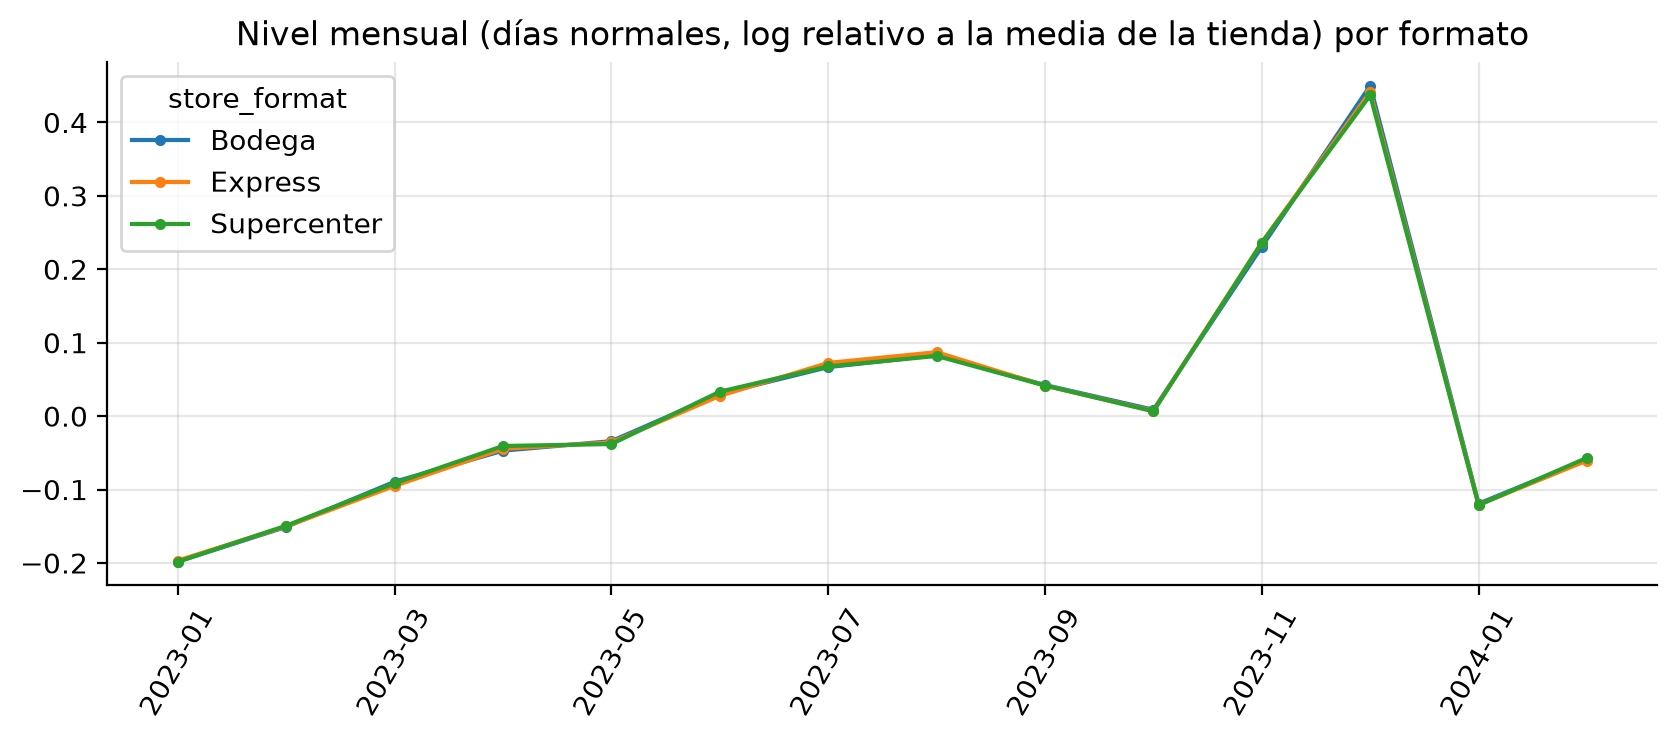

Rango máx−mín entre formatos dentro de un mismo mes: 0.013 log | variación del nivel común entre el mes más bajo y el más alto: 0.64 log

Participación por categoría entre tiendas (%):


,media,desv. est. entre tiendas,mín,máx
category,,,,
Abarrotes,25.130,0.200,24.580,25.720
Bebidas,12.870,0.130,12.610,13.230
Cuidado_Personal,10.560,0.110,10.260,10.840
Electronica,18.090,0.170,17.740,18.520
Hogar,16.860,0.150,16.520,17.250
Ropa,16.480,0.130,16.080,16.740


In [12]:
# Tendencia común: los formatos se mueven en paralelo, pero el nivel común cambia mucho a lo largo del año
normal = sd_[~sd_.date.isin(c.loc[c.is_holiday | c.is_buen_fin | c.is_navidad_season, 'date'])].copy()
normal['lc'] = np.log(normal.amt); normal['lc'] -= normal.groupby('store_id').lc.transform('mean')
mm = normal.assign(mes=normal.date.dt.to_period('M').astype(str)).groupby(['mes', 'store_format']).lc.mean().unstack()
ax = mm.plot(marker='o', ms=3, title='Nivel mensual (días normales, log relativo a la media de la tienda) por formato'); ax.set_xlabel('')
plt.xticks(rotation=60); plt.show()
print(f'Rango máx−mín entre formatos dentro de un mismo mes: {(mm.max(axis=1) - mm.min(axis=1)).max():.3f} log | variación del nivel común entre el mes más bajo y el más alto: {mm.mean(axis=1).max() - mm.mean(axis=1).min():.2f} log')
mix = obs.groupby(['store_id', 'category']).amount_total.sum().unstack(); mix = mix.div(mix.sum(axis=1), axis=0) * 100
print('\nParticipación por categoría entre tiendas (%):'); pd.DataFrame({'media': mix.mean(), 'desv. est. entre tiendas': mix.std(), 'mín': mix.min(), 'máx': mix.max()}).round(2)

**Lectura.**
- **Nivel:** el formato explica el 78 % de la varianza del nivel entre tiendas; con todos los atributos llega al 89 %. Frente a una Bodega, un Supercenter vende ≈ +61 % y un Express ≈ −52 %. El **nivel socioeconómico** aporta además del formato y de forma ordenada (ΔR² = 0.075, p = 0.001): frente a A/B, B ≈ −14 %, C+ ≈ −29 %, C ≈ −37 % (solo hay 5 tiendas A/B, así que esa referencia es imprecisa).
- **Nada más aporta** una vez conocido el formato (p > 0.08): región, farmacia, gasolinera, año de apertura, m² y cajas. `size_sqm` y `num_checkouts` parecen explicar mucho por sí solos (R² ≈ 0.6) pero dentro de un mismo formato su correlación con el nivel es ≈ 0: son el formato disfrazado. Además ningún Express tiene farmacia ni gasolinera, así que con 80 tiendas no se pueden separar esos efectos del formato.
- **Dinámica:** los eventos pegan distinto por formato (Buen Fin ≈ ×3.3–3.4 en Bodega y Supercenter vs. ×2.7 en Express, frente a los mismos días de la semana 4–7 semanas antes; esta base incluye la rampa de otoño, por eso las magnitudes son mayores que contra septiembre). Los tres formatos se mueven en paralelo mes a mes (diferencia máx. 0.013 log), pero el **nivel común cambia ≈ 0.64 log (≈ 90 %) entre el mes más bajo y el más alto**: con 14 meses no se puede separar tendencia de estacionalidad anual.
- **Mix de categorías:** prácticamente idéntico en todas las tiendas (p. ej. Abarrotes 25.1 % ± 0.2 pp).

**Decisión.** Modelo **global** (no uno por formato) con `store_format` y `socioeconomic_level` como variables y sus interacciones con calendario/eventos; sin `region`, farmacia, gasolinera ni tamaño en la versión base (se pueden probar con ablación en la Fase 3). El nivel propio de cada tienda que los atributos no explican lo capturan los rezagos de su propia serie. Nunca se usa `month`/`week_of_year` como variable: con 14 meses cada valor se observa una vez y el modelo lo usaría como índice de tiempo.

## 5. Promoción: ¿se asignó al azar? Pruebas formales

In [13]:
rows = []
for col in ['category', 'store_format', 'region', 'socioeconomic_level', 'has_pharmacy', 'has_fuel_station', 'day_of_week', 'is_payday', 'is_official_holiday', 'is_buen_fin', 'is_navidad_season', 'month']:
    ct = pd.crosstab(obs[col], obs.has_promotion); chi2, pv, *_ = stats.chi2_contingency(ct)
    rate = obs.groupby(col, observed=True).has_promotion.mean() * 100
    rows.append({'variable': col, 'tasa mín %': rate.min(), 'tasa máx %': rate.max(), 'p (chi²)': pv})
R = pd.DataFrame(rows).set_index('variable'); print(f'Tasa global de promoción: {obs.has_promotion.mean():.2%}'); print(R.to_string())
print(f'\nKS de los p-valores contra U(0,1): p = {stats.kstest(R["p (chi²)"], "uniform").pvalue:.2f}   (si fuera asignación dirigida esperaríamos p-valores pequeños)')

Tasa global de promoción: 19.98%
                     tasa mín %  tasa máx %  p (chi²)
variable                                             
category                 19.881      20.189     0.938
store_format             19.938      20.061     0.855
region                   19.736      20.196     0.316
socioeconomic_level      19.639      20.336     0.019
has_pharmacy             19.963      20.039     0.742
has_fuel_station         19.970      19.980     0.964
day_of_week              19.734      20.271     0.753
is_payday                19.960      20.216     0.481
is_official_holiday      19.420      19.996     0.251
is_buen_fin              19.974      20.260     0.777
is_navidad_season        19.634      20.002     0.299
month                    19.674      20.544     0.653

KS de los p-valores contra U(0,1): p = 0.42   (si fuera asignación dirigida esperaríamos p-valores pequeños)


In [14]:
pr = obs.groupby('store_id').has_promotion.agg(['mean', 'size']); p0 = obs.has_promotion.mean()
print(f'Dispersión de la tasa entre tiendas: observada {pr["mean"].std()*100:.2f} pp | esperada por azar {np.sqrt(p0*(1-p0)/pr["size"].mean())*100:.2f} pp')
day = obs.groupby('date').has_promotion.agg(['mean', 'size']).query('size == 480')
print(f'Dispersión de la fracción diaria de series en promoción: observada {day["mean"].std()*100:.2f} pp | esperada {np.sqrt(p0*(1-p0)/480)*100:.2f} pp')
q = obs.sort_values(['serie', 'date']); prev = q.groupby('serie').has_promotion.shift()
print(f'P(promo | promo ayer) = {q.has_promotion[prev == 1].mean():.3f} | P(promo | sin promo ayer) = {q.has_promotion[prev == 0].mean():.3f}')
runs = q.groupby('serie').has_promotion.apply(lambda x: x.groupby((x != x.shift()).cumsum()).agg(['first', 'size']).query('first == 1')['size'])
print(f'Duración de una promoción: media {runs.mean():.3f} días | esperada si cada día es Bernoulli({p0:.2f}): {1/(1-p0):.3f}')
# ¿se promociona según el desempeño reciente? (asignación dirigida / causalidad inversa)
q['lc'] = np.log(q.amount_total) - q.groupby('serie').amount_total.transform(lambda x: np.log(x).mean())
for k in (1, 7, 14):
    lag = q.groupby('serie').lc.shift(k); dif = lag[q.has_promotion == 1].mean() - lag[q.has_promotion == 0].mean()
    se = np.sqrt(lag[q.has_promotion == 1].var() / (q.has_promotion == 1).sum() + lag[q.has_promotion == 0].var() / (q.has_promotion == 0).sum())
    print(f'Venta (log, centrada) {k:2d} días antes: promo − no promo = {dif:+.4f} (±{1.96*se:.4f})')

Dispersión de la tasa entre tiendas: observada 0.83 pp | esperada por azar 0.79 pp
Dispersión de la fracción diaria de series en promoción: observada 1.81 pp | esperada 1.82 pp
P(promo | promo ayer) = 0.200 | P(promo | sin promo ayer) = 0.200
Duración de una promoción: media 1.249 días | esperada si cada día es Bernoulli(0.20): 1.250
Venta (log, centrada)  1 días antes: promo − no promo = +0.0012 (±0.0044)
Venta (log, centrada)  7 días antes: promo − no promo = -0.0007 (±0.0044)
Venta (log, centrada) 14 días antes: promo − no promo = -0.0017 (±0.0045)


**Lectura.** Cada prueba es consistente con una asignación **aleatoria** (Bernoulli ≈ 0.20 por serie y día):
- La tasa de promoción es ≈ 20 % en todos los segmentos; los p-valores de las 12 pruebas χ² no se distinguen de uniformes (KS p = 0.42). El único p < 0.05 (nivel socioeconómico, p = 0.019; tasas de 19.6 % a 20.3 %) es lo esperable al hacer 12 pruebas.
- La dispersión de la tasa entre tiendas (0.83 vs. 0.79 pp) y de la fracción diaria de series en promoción (1.81 vs. 1.82 pp) coincide con lo esperado por azar.
- No hay memoria: P(promo | promo ayer) = P(promo | sin promo ayer) = 0.200, y la duración media de una promoción (1.249 días) iguala la geométrica esperada (1.250).
- **No se promociona según el desempeño reciente:** la venta de 1, 7 y 14 días antes no difiere entre filas con y sin promoción (|dif.| < 0.002 log, dentro de ±0.0045).

**Implicaciones para la Capa 2.**
1. El riesgo de sesgo de selección (confusión con calendario o tienda) es bajo: la promoción funciona como un experimento aleatorizado a nivel serie-día. Aun así el modelo controla por efectos fijos y calendario y se documenta como supuesto.
2. Como la promoción casi no tiene señal predecible, no debe esperarse que mejore el pronóstico.
3. El resultado puede ser un efecto nulo o muy pequeño: se reporta con intervalo de confianza y no se asume positivo.

## 6. Ruido irreducible y granularidad de la meta
Si el error diario fuera ruido sin estructura, ningún modelo podría bajar de cierto WAPE. Se estima con un modelo estructural en logaritmos **con efecto fijo por fecha** (supone conocido el choque común de la cadena cada día, así que es un piso optimista): efectos de serie, de fecha, categoría × día de la semana y promoción.

In [15]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import Ridge
import scipy.sparse as sp
r = obs.copy(); r['y'] = np.log(r.amount_total); r['cat_dow'] = r.category + '|' + r.day_of_week.astype(str); r['fecha'] = r.date.astype(str)
X = sp.hstack([OneHotEncoder().fit_transform(r[['serie', 'fecha', 'cat_dow']]), sp.csr_matrix(r[['has_promotion']].values.astype(float))]).tocsr()
mod = Ridge(alpha=1e-3, solver='sparse_cg', max_iter=2000).fit(X, r.y); r['yhat'] = np.exp(mod.predict(X)); resid = r.y - mod.predict(X)
print(f'σ residual (log): {resid.std():.3f} | autocorrelación lag-1/7/28 del residuo por serie:',
      [round(resid.groupby(r.serie).apply(lambda x: x.autocorr(k)).mean(), 3) for k in (1, 7, 28)])
r['semana'] = r.date.dt.to_period('W'); full = r.groupby(['serie', 'semana']).date.transform('size') == 7
levels = {'serie × día': ['serie', 'date'], 'tienda × día': ['store_id', 'date'], 'categoría × día': ['category', 'date'], 'total × día': ['date']}
wk = {'serie × semana': ['serie', 'semana'], 'tienda × semana': ['store_id', 'semana'], 'categoría × semana': ['category', 'semana'], 'total × semana': ['semana']}
out = {}
for name, k in {**levels, **wk}.items():
    base_df = r[full] if 'semana' in k else r
    g = base_df.groupby(k)[['amount_total', 'yhat']].sum(); out[name] = {'WAPE piso %': wape(g.amount_total, g.yhat) * 100, 'MAPE piso %': mape(g.amount_total, g.yhat) * 100}
pd.DataFrame(out).T.round(1)

σ residual (log): 0.198 | autocorrelación lag-1/7/28 del residuo por serie: [np.float64(0.003), np.float64(0.001), np.float64(-0.0)]


,WAPE piso %,MAPE piso %
serie × día,15.600,16.100
tienda × día,7.000,6.700
categoría × día,2.600,2.400
total × día,2.100,1.900
serie × semana,6.500,6.200
tienda × semana,3.400,3.100
categoría × semana,2.100,1.900
total × semana,2.100,1.900


**Lectura.**
- Tras quitar nivel de serie, choque diario de la cadena, perfil semanal por categoría y promoción, el residuo tiene **σ ≈ 0.20 en logaritmos y no tiene autocorrelación** (0.003, 0.001 y 0.000 a 1, 7 y 28 días): es ruido sin patrón que un modelo pueda aprender.
- Al agregar, el ruido se compensa. **Aun con un pronóstico perfecto, a tienda × categoría × día no se baja de WAPE ≈ 15.6 %**; a tienda × categoría × **semana** el piso es ≈ 6.5 %, a tienda × semana ≈ 3.4 % y a nivel categoría o total ≈ 2 %.
- Son pisos **optimistas** (se ajustan en la muestra y suponen conocido el choque común de la cadena cada día): un pronóstico real queda por encima, y un error diario por debajo de ≈ 15 % debe leerse como alarma de fuga de información.

**Implicaciones para las métricas.**
- La meta **MAPE < 15 % a nivel serie-día** del plan está en el piso de ruido: no es exigible.
- La métrica principal será **WAPE** (pondera por volumen), con **MAPE secundaria y sesgo siempre a la vista**: el MAPE favorece sub-pronosticar, lo cual en inventario implica riesgo de desabasto.
- El modelo se entrena a nivel diario y la meta se mide en **tienda × categoría × semana** (grano de la decisión de reposición, con piso ≈ 6.5 %), contra baselines simples.

## Conclusiones
| Tema | Hallazgo | Decisión |
|---|---|---|
| Nulos | MCAR; efectivo siempre junto con su monto | `NaN` + bandera; no son features |
| `total_transactions` | ≠ efectivo+tarjeta ⇔ promoción (38,295/38,295); ticket coherente con transacciones pagadas | No usar como target ni para uplift; monto como medida |
| Calendario | Consistente; `is_holiday` incluye Buen Fin; Semana Santa solo 2 días | Usar `is_official_holiday`; no modelar Semana Santa 2024 |
| Extremos | 98 % en eventos reales | No recortar; evaluar eventos aparte |
| Atributos de tienda | Formato (78 %) + nivel socioeconómico; el resto es proxy del formato | Modelo global con formato y nivel socioeconómico |
| Promoción | Compatible con asignación aleatoria (χ², dispersión, memoria, desempeño previo) | Efectos fijos + calendario; reportar IC; esperar efecto pequeño |
| Ruido | Piso WAPE ≈ 15.6 % serie-día, ≈ 6.5 % serie-semana | Entrenar diario, evaluar en serie × semana con WAPE |